In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import interact_manual, IntSlider

# Sample sequences
query = "ATGCTAGCTAGGCTA"
target = "TTGCTAGATAGGCTA"

k = 3  # k-mer size

# Generate k-mers from query
query_kmers = [query[i:i+k] for i in range(len(query)-k+1)]

# Find all seed matches (positions where k-mer occurs in target)
seed_matches = []
for i, qmer in enumerate(query_kmers):
    for j in range(len(target)-k+1):
        tmer = target[j:j+k]
        if qmer == tmer:
            seed_matches.append((i, j))  # (query pos, target pos)

def extend_seed(q_start, t_start):
    """
    Extend the match from the seed positions in both directions to form alignment.
    """
    max_len = min(len(query) - q_start, len(target) - t_start)
    length = 0
    # Extend while characters match
    while length < max_len and query[q_start + length] == target[t_start + length]:
        length += 1
    return length

def plot_alignment(step=0):
    fig, ax = plt.subplots(figsize=(14,4))
    ax.axis('off')
    ax.set_title("MegaBLAST Seed-and-Extend Demo", fontsize=16, weight='bold')
    
    # Display sequences with monospace font
    y_query = 1.5
    y_target = 0.5
    ax.text(0, y_query, "Query:  ", fontsize=14, fontfamily='monospace', verticalalignment='center')
    ax.text(0, y_target, "Target: ", fontsize=14, fontfamily='monospace', verticalalignment='center')
    
    # Print sequences spaced out for coloring
    x_start = 70
    spacing = 18  # spacing between letters
    
    # Helper to draw letters with background color for alignment
    def draw_seq(y, seq, colors=None):
        for i, base in enumerate(seq):
            x = x_start + i * spacing
            if colors and colors[i] != 'none':
                rect = Rectangle((x-7, y-0.3), 14, 0.8, color=colors[i], alpha=0.5)
                ax.add_patch(rect)
            ax.text(x, y, base, fontsize=20, fontfamily='monospace', weight='bold', ha='center', va='center')
    
    # Draw full query and target sequences in gray
    draw_seq(y_query, query, colors=['#ddd']*len(query))
    draw_seq(y_target, target, colors=['#ddd']*len(target))
    
    # Draw all seed matches as arrows
    for (qpos, tpos) in seed_matches:
        qx = x_start + qpos * spacing
        ty = y_target + 0.2
        ax.annotate('', xy=(qx, y_query - 0.2), xytext=(qx, ty),
                    arrowprops=dict(arrowstyle="->", color='lightgray', lw=1))
    
    if step > 0 and step <= len(seed_matches):
        qpos, tpos = seed_matches[step-1]
        ext_len = extend_seed(qpos, tpos)
        
        # Highlight seed and extended alignment
        # Colors: green for match, red for mismatch (though here extension is exact matches)
        aligned_query = query[qpos:qpos+ext_len]
        aligned_target = target[tpos:tpos+ext_len]
        
        colors = []
        for i in range(ext_len):
            if aligned_query[i] == aligned_target[i]:
                colors.append('#7CFC00')  # light green for match
            else:
                colors.append('#FF6347')  # tomato red for mismatch
        
        # Draw background for extended alignment on query and target
        draw_seq(y_query, query, colors=['none']*qpos + colors + ['none']*(len(query) - qpos - ext_len))
        draw_seq(y_target, target, colors=['none']*tpos + colors + ['none']*(len(target) - tpos - ext_len))
        
        # Highlight current seed match with bold underline
        for i in range(k):
            qx = x_start + (qpos + i) * spacing
            ax.plot([qx - 8, qx + 8], [y_query - 0.6, y_query - 0.6], color='orange', lw=3)
            tx = x_start + (tpos + i) * spacing
            ax.plot([tx - 8, tx + 8], [y_target - 0.6, y_target - 0.6], color='orange', lw=3)
        
        # Text description
        ax.text(0, -0.5, f"Step {step}: Seed match at query pos {qpos}, target pos {tpos}", fontsize=14)
        ax.text(0, -1, f"Extended alignment length: {ext_len} bases", fontsize=14)
    
    plt.ylim(-2, 2)
    plt.show()

interact_manual(plot_alignment, step=IntSlider(min=0, max=len(seed_matches), step=1, description="Seed step"))


interactive(children=(IntSlider(value=0, description='Seed step', max=19), Button(description='Run Interact', …

<function __main__.plot_alignment(step=0)>

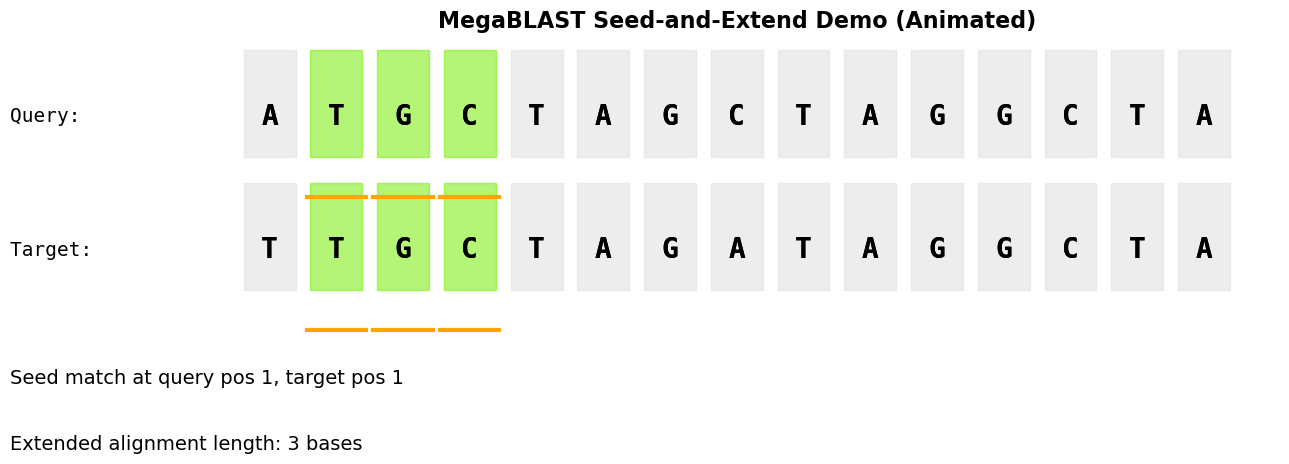

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import Dropdown, Button, HBox, VBox, Label, Output
import asyncio
import threading

# Sequences and k-mer size
query = "ATGCTAGCTAGGCTA"
target = "TTGCTAGATAGGCTA"
k = 3

query_kmers = [query[i:i+k] for i in range(len(query)-k+1)]
seed_matches = []
for i, qmer in enumerate(query_kmers):
    for j in range(len(target)-k+1):
        tmer = target[j:j+k]
        if qmer == tmer:
            seed_matches.append((i, j))

x_start = 70
spacing = 18

# Drawing utilities
def draw_seq(ax, y, seq, colors=None):
    for i, base in enumerate(seq):
        x = x_start + i * spacing
        if colors and colors[i] != 'none':
            rect = Rectangle((x-7, y-0.3), 14, 0.8, color=colors[i], alpha=0.5)
            ax.add_patch(rect)
        ax.text(x, y, base, fontsize=20, fontfamily='monospace', weight='bold', ha='center', va='center')

class MegaBLASTDemo:
    def __init__(self):
        self.seed_index = 0
        self.extension_len = k  # start at seed length
        self.running = False
        self.fig, self.ax = plt.subplots(figsize=(14,4))
        self.out = Output()
        
        # Widgets
        self.seed_dropdown = Dropdown(options=[f"Seed {i+1} (q:{q}, t:{t})" for i,(q,t) in enumerate(seed_matches)],
                                      description='Seed:')
        self.run_button = Button(description="Run", button_style='success')
        self.pause_button = Button(description="Pause", button_style='warning', disabled=True)
        self.status_label = Label()
        
        self.run_button.on_click(self.start_animation)
        self.pause_button.on_click(self.pause_animation)
        self.seed_dropdown.observe(self.change_seed, names='value')
        
        self.controls = HBox([self.seed_dropdown, self.run_button, self.pause_button, self.status_label])
        self.vbox = VBox([self.controls, self.out])
        
        self.draw_initial()
    
    def draw_initial(self):
        with self.out:
            self.ax.clear()
            self.ax.axis('off')
            self.ax.set_title("MegaBLAST Seed-and-Extend Demo (Animated)", fontsize=16, weight='bold')
            y_query = 1.5
            y_target = 0.5
            self.ax.text(0, y_query, "Query:  ", fontsize=14, fontfamily='monospace', verticalalignment='center')
            self.ax.text(0, y_target, "Target: ", fontsize=14, fontfamily='monospace', verticalalignment='center')
            
            # Full sequences faded
            draw_seq(self.ax, y_query, query, colors=['#ddd']*len(query))
            draw_seq(self.ax, y_target, target, colors=['#ddd']*len(target))
            
            # Arrows for all seeds
            for (qpos, tpos) in seed_matches:
                qx = x_start + qpos * spacing
                ty = y_target + 0.2
                self.ax.annotate('', xy=(qx, y_query - 0.2), xytext=(qx, ty),
                            arrowprops=dict(arrowstyle="->", color='lightgray', lw=1))
            
            self.fig.canvas.draw_idle()
    
    def draw_step(self, seed_index, ext_len):
        self.ax.clear()
        self.ax.axis('off')
        self.ax.set_title("MegaBLAST Seed-and-Extend Demo (Animated)", fontsize=16, weight='bold')
        y_query = 1.5
        y_target = 0.5
        self.ax.text(0, y_query, "Query:  ", fontsize=14, fontfamily='monospace', verticalalignment='center')
        self.ax.text(0, y_target, "Target: ", fontsize=14, fontfamily='monospace', verticalalignment='center')
        
        # Faded full sequences
        draw_seq(self.ax, y_query, query, colors=['#ddd']*len(query))
        draw_seq(self.ax, y_target, target, colors=['#ddd']*len(target))
        
        qpos, tpos = seed_matches[seed_index]
        max_ext = min(len(query)-qpos, len(target)-tpos)
        ext_len = min(ext_len, max_ext)
        
        aligned_query = query[qpos:qpos+ext_len]
        aligned_target = target[tpos:tpos+ext_len]
        
        colors = []
        for i in range(ext_len):
            if aligned_query[i] == aligned_target[i]:
                colors.append('#7CFC00')
            else:
                colors.append('#FF6347')
        
        # Highlight extended alignment
        draw_seq(self.ax, y_query, query, colors=['none']*qpos + colors + ['none']*(len(query) - qpos - ext_len))
        draw_seq(self.ax, y_target, target, colors=['none']*tpos + colors + ['none']*(len(target) - tpos - ext_len))
        
        # Highlight seed k-mer underline
        for i in range(k):
            qx = x_start + (qpos + i) * spacing
            self.ax.plot([qx - 8, qx + 8], [y_query - 0.6, y_query - 0.6], color='orange', lw=3)
            tx = x_start + (tpos + i) * spacing
            self.ax.plot([tx - 8, tx + 8], [y_target - 0.6, y_target - 0.6], color='orange', lw=3)
        
        # Text info
        self.ax.text(0, -0.5, f"Seed match at query pos {qpos}, target pos {tpos}", fontsize=14)
        self.ax.text(0, -1, f"Extended alignment length: {ext_len} bases", fontsize=14)
        self.fig.canvas.draw_idle()
    
    def change_seed(self, change):
        self.seed_index = self.seed_dropdown.index
        self.extension_len = k
        self.running = False
        self.pause_button.disabled = True
        self.run_button.disabled = False
        self.status_label.value = ""
        self.draw_step(self.seed_index, self.extension_len)
    
    def pause_animation(self, b):
        self.running = False
        self.status_label.value = "Paused"
        self.pause_button.disabled = True
        self.run_button.disabled = False
    
    def start_animation(self, b):
        if self.running:
            return
        self.running = True
        self.pause_button.disabled = False
        self.run_button.disabled = True
        self.status_label.value = "Running..."
        asyncio.ensure_future(self.animate_extension())
    
    async def animate_extension(self):
        max_ext = min(len(query)-seed_matches[self.seed_index][0], len(target)-seed_matches[self.seed_index][1])
        while self.extension_len < max_ext and self.running:
            self.extension_len += 1
            self.draw_step(self.seed_index, self.extension_len)
            await asyncio.sleep(0.7)  # pause between steps
        if self.extension_len >= max_ext:
            self.status_label.value = "Extension complete"
            self.pause_button.disabled = True
            self.run_button.disabled = False
            self.running = False

# Create and display the demo
demo = MegaBLASTDemo()
display(demo.vbox)

# Initial draw
demo.draw_step(0, k)


In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import interact, IntSlider, Play, jslink, HBox, VBox

# --- your sequences and k ---
query  = "ATGCTAGCTAGGCTA"
target = "TTGCTAGATAGGCTA"
k = 3

# --- helper functions ---
def get_kmers(seq, k):
    return [(i, seq[i:i+k]) for i in range(len(seq)-k+1)]

def extend_seed(q_start, t_start):
    """Extend from the seed forward until mismatch or end."""
    max_len = min(len(query)-q_start, len(target)-t_start)
    l = 0
    while l < max_len and query[q_start + l] == target[t_start + l]:
        l += 1
    return l

# --- find all raw seed matches ---
query_kmers  = get_kmers(query, k)
target_kmers = get_kmers(target, k)

seed_matches = []
for qi, qmer in query_kmers:
    for ti, tmer in target_kmers:
        if qmer == tmer:
            ext_len = extend_seed(qi, ti)
            seed_matches.append((qi, ti, ext_len))

# --- sort by extension length descending ---
seed_matches.sort(key=lambda x: -x[2])

# --- plotting routine ---
def plot_alignment(step=1):
    fig, ax = plt.subplots(figsize=(14,4))
    ax.axis('off')
    ax.set_title("MegaBLAST Seed‐and‐Extend Demo (best‐first)", fontsize=16, weight='bold')

    # draw full sequences in light gray
    yq, yt = 1.5, 0.5
    x0, spacing = 70, 18
    def draw_seq(y, seq, colors=None):
        for i, base in enumerate(seq):
            x = x0 + i*spacing
            if colors and colors[i] != 'none':
                ax.add_patch(Rectangle((x-7, y-0.3), 14, 0.8,
                                       color=colors[i], alpha=0.5))
            ax.text(x, y, base, fontsize=20, fontfamily='monospace',
                    weight='bold', ha='center', va='center')

    # grey everything
    draw_seq(yq, query,  colors=['#ddd']*len(query))
    draw_seq(yt, target, colors=['#ddd']*len(target))

    # draw all arrows in the background
    for (qi, ti, _) in seed_matches:
        xq = x0 + qi*spacing
        yt0 = yt + 0.2
        ax.annotate('', xy=(xq, yq-0.2), xytext=(xq, yt0),
                    arrowprops=dict(arrowstyle='->', color='lightgray', lw=1))

    # if step in range, highlight that seed
    if 1 <= step <= len(seed_matches):
        qi, ti, ext_len = seed_matches[step-1]
        aligned_q = query[qi:qi+ext_len]
        aligned_t = target[ti:ti+ext_len]
        colors = ['#7CFC00' if aligned_q[i]==aligned_t[i] else '#FF6347'
                  for i in range(ext_len)]

        # over-draw the extension
        draw_seq(yq, query,
                 colors=['none']*qi + colors + ['none']*(len(query)-qi-ext_len))
        draw_seq(yt, target,
                 colors=['none']*ti + colors + ['none']*(len(target)-ti-ext_len))

        # underline the k-mer seed in orange
        for i in range(k):
            xq = x0 + (qi+i)*spacing
            ax.plot([xq-8, xq+8], [yq-0.6]*2, color='orange', lw=3)
            xt = x0 + (ti+i)*spacing
            ax.plot([xt-8, xt+8], [yt-0.6]*2, color='orange', lw=3)

        # annotations
        ax.text(0, -0.5,
                f"Step {step}/{len(seed_matches)}: picked seed at query pos {qi}, target pos {ti}",
                fontsize=14)
        ax.text(0, -1,
                f"Extension length: {ext_len} bases (k={k})",
                fontsize=14)

    plt.ylim(-2, 2)
    plt.show()

# --- interactive widgets ---
n_seeds = len(seed_matches)
step_slider = IntSlider(value=1, min=1, max=n_seeds, step=1,
                        description="Seed #", continuous_update=True)
play = Play(value=1, min=1, max=n_seeds, step=1, interval=800,
            description="▶︎ Play", disabled=False)
jslink((play, 'value'), (step_slider, 'value'))

ui = HBox([play, step_slider])
out = interact(plot_alignment, step=step_slider)

# display both
display(VBox([ui, out.widget]))  # Note: out.widget is the output area


interactive(children=(IntSlider(value=1, description='Seed #', max=19, min=1), Output()), _dom_classes=('widge…

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import Play, IntSlider, jslink, HBox, VBox, interactive_output
from IPython.display import display

# --- Data and parameters ---
query  = "ATGCTAGCTAGGCTA"
target = "TTGCTAGATAGGCTA"
k = 3

# --- Precompute k-mers and hash table ---
def extend_seed(q_start, t_start):
    max_len = min(len(query)-q_start, len(target)-t_start)
    l = 0
    while l < max_len and query[q_start + l] == target[t_start + l]:
        l += 1
    return l

query_kmers = [(i, query[i:i+k]) for i in range(len(query)-k+1)]
target_kmers = [(j, target[j:j+k]) for j in range(len(target)-k+1)]

hash_table = {}
events = []

# 1. Hash-building events
for qi, qmer in query_kmers:
    events.append({'type':'hash', 'qpos':qi})
    hash_table.setdefault(qmer, []).append(qi)

# 2. Scanning & seeding events
for ti, tmer in target_kmers:
    matches = hash_table.get(tmer, [])
    events.append({'type':'scan', 'tpos':ti, 'matches':matches})
    for qi in matches:
        events.append({'type':'seed', 'qpos':qi, 'tpos':ti})
        ext_len = extend_seed(qi, ti)
        events.append({'type':'extend', 'qpos':qi, 'tpos':ti, 'length':ext_len})

# --- Plotting function ---
fig, ax = plt.subplots(figsize=(12, 4))
plt.close(fig)  # we'll use display in the update function

def draw_sequences(highlight=None):
    ax.clear()
    ax.axis('off')
    yq, yt = 1.5, 0.5
    x0, spacing = 1, 1
    # Draw query and target
    for y, seq in [(yq, query), (yt, target)]:
        for i, base in enumerate(seq):
            color = 'lightgray'
            alpha = 0.5
            if highlight and highlight['type'] in ('hash', 'seed', 'extend') and y == yq:
                if 'qpos' in highlight and i >= highlight['qpos'] and i < highlight.get('qpos',0)+highlight.get('length',k):
                    color = 'skyblue' if highlight['type']=='hash' else 'lightgreen'
                    alpha = 0.7
            if highlight and highlight['type']=='scan' and y == yt:
                if i >= highlight['tpos'] and i < highlight['tpos']+k:
                    color = 'khaki'; alpha = 0.7
            if highlight and highlight['type']=='extend' and y == yt:
                if i >= highlight['tpos'] and i < highlight['tpos']+highlight['length']:
                    color = 'lightgreen'; alpha = 0.7
            ax.add_patch(Rectangle((x0 + i*spacing - 0.4, y - 0.4), 0.8, 0.8,
                                   color=color, alpha=alpha))
            ax.text(x0 + i*spacing, y, base, fontsize=16, ha='center', va='center',
                    fontfamily='monospace')
    # Draw arrows for seed events
    if highlight and highlight['type']=='seed':
        qi, ti = highlight['qpos'], highlight['tpos']
        ax.annotate('', xy=(x0 + qi*spacing, yq-0.2),
                    xytext=(x0 + ti*spacing, yt+0.2),
                    arrowprops=dict(arrowstyle='->', color='tomato', lw=2))
    ax.set_xlim(0, x0 + max(len(query), len(target))*spacing)
    ax.set_ylim(-0.5, 2)

def update(step):
    evt = events[step]
    draw_sequences(highlight=evt)
    ax.set_title(f"Step {step+1}/{len(events)}: {evt['type'].capitalize()}", fontsize=14)
    display(fig)

# --- Interactive widgets ---
play = Play(min=0, max=len(events)-1, interval=800, description="▶ Play")
slider = IntSlider(min=0, max=len(events)-1, description='Step')
jslink((play, 'value'), (slider, 'value'))

out = interactive_output(update, {'step': slider})
display(VBox([HBox([play, slider]), out]))


In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import Play, IntSlider, jslink, HBox, VBox, interactive_output
from IPython.display import display

# --- Data and parameters ---
query  = "ATGCTAGCTAGGCTA"
target = "TTGCTAGATAGGCTA"
k = 3

# --- Helper to extend a seed forward until mismatch/end ---
def extend_seed(q_start, t_start):
    max_len = min(len(query)-q_start, len(target)-t_start)
    l = 0
    while l < max_len and query[q_start + l] == target[t_start + l]:
        l += 1
    return l

# --- Precompute k-mers & build event list ---
query_kmers  = [(i, query[i:i+k]) for i in range(len(query)-k+1)]
target_kmers = [(j, target[j:j+k]) for j in range(len(target)-k+1)]

hash_table = {}
events = []

# 1) Hash-building
for qi, qmer in query_kmers:
    events.append({'type':'hash', 'qpos':qi})
    hash_table.setdefault(qmer, []).append(qi)

# 2) Scanning / seeding / extending
for ti, tmer in target_kmers:
    matches = hash_table.get(tmer, [])
    events.append({'type':'scan', 'tpos':ti, 'matches':matches})
    for qi in matches:
        events.append({'type':'seed', 'qpos':qi, 'tpos':ti})
        ext_len = extend_seed(qi, ti)
        events.append({'type':'extend', 'qpos':qi, 'tpos':ti, 'length':ext_len})

# 3) Pick the best extension (longest) and add two more steps
#    a) “select” highlights that seed
#    b) “summary” shows percent identity
ext_events = [e for e in events if e['type']=='extend']
best = max(ext_events, key=lambda e: e['length'])
identity = round(best['length'] / len(query) * 100, 1)

events.append({
    'type':'select',
    'qpos':  best['qpos'],
    'tpos':  best['tpos'],
    'length':best['length']
})
events.append({
    'type':'summary',
    'qpos':  best['qpos'],
    'tpos':  best['tpos'],
    'length':best['length'],
    'identity': identity
})


# --- Plotting setup ---
fig, ax = plt.subplots(figsize=(12, 4))
plt.close(fig)  # we’ll explicitly display it in the update()

def draw_sequences(highlight=None):
    ax.clear()
    ax.axis('off')
    yq, yt = 1.5, 0.5
    x0, spacing = 1, 1

    # draw query/target with default gray
    def draw_line(y, seq, region=None, color='#ddd', alpha=0.5):
        for i, base in enumerate(seq):
            # if region specified and we're in it, override color/alpha
            if region and region[0] <= i < region[0] + region[1]:
                c, a = color, 0.7
            else:
                c, a = '#ddd', 0.5
            ax.add_patch(Rectangle((x0 + i*spacing - 0.4, y - 0.4),
                                   0.8, 0.8, color=c, alpha=a))
            ax.text(x0 + i*spacing, y, base, fontsize=16,
                    ha='center', va='center', fontfamily='monospace')

    # handle each line
    # for summary we’ll recolor in green, for select orange, else default
    if highlight and highlight['type']=='select':
        # highlight best seed in orange
        region = (highlight['qpos'], highlight['length'])
        draw_line(yq, query, region=region, color='orange')
        region = (highlight['tpos'], highlight['length'])
        draw_line(yt, target, region=region, color='orange')
        # arrow
        ax.annotate('', xy=(x0 + highlight['qpos']*spacing, yq-0.2),
                    xytext=(x0 + highlight['tpos']*spacing, yt+0.2),
                    arrowprops=dict(arrowstyle='->', color='orange', lw=2))
    elif highlight and highlight['type']=='summary':
        # highlight best seed in green, then write identity text
        region_q = (highlight['qpos'], highlight['length'])
        region_t = (highlight['tpos'], highlight['length'])
        draw_line(yq, query, region=region_q, color='limegreen')
        draw_line(yt, target, region=region_t, color='limegreen')
        ax.text(0, -0.5,
                f"Best match = {highlight['length']} bases  |  Identity = {highlight['identity']}%",
                fontsize=14, weight='bold')
    else:
        # default or intermediate events
        # always draw full lines first
        draw_line(yq, query)
        draw_line(yt, target)

        if highlight:
            t = highlight['type']
            if t=='hash':
                draw_line(yq, query,
                          region=(highlight['qpos'], k),
                          color='skyblue')
            elif t=='scan':
                draw_line(yt, target,
                          region=(highlight['tpos'], k),
                          color='khaki')
            elif t=='seed':
                # draw both k-mer regions plus arrow
                draw_line(yq, query,
                          region=(highlight['qpos'], k),
                          color='skyblue')
                draw_line(yt, target,
                          region=(highlight['tpos'], k),
                          color='khaki')
                ax.annotate('', xy=(x0 + highlight['qpos']*spacing, yq-0.2),
                            xytext=(x0 + highlight['tpos']*spacing, yt+0.2),
                            arrowprops=dict(arrowstyle='->', color='tomato', lw=2))
            elif t=='extend':
                # draw full extended region in green
                l = highlight['length']
                draw_line(yq, query,
                          region=(highlight['qpos'], l),
                          color='lightgreen')
                draw_line(yt, target,
                          region=(highlight['tpos'], l),
                          color='lightgreen')

    ax.set_xlim(0, x0 + max(len(query), len(target))*spacing)
    ax.set_ylim(-0.5, 2)


def update(step):
    evt = events[step]
    draw_sequences(highlight=evt)
    ax.set_title(f"Step {step+1}/{len(events)} – {evt['type'].capitalize()}", fontsize=14)
    display(fig)


# --- Widgets ---
play   = Play(min=0, max=len(events)-1, interval=800, description="▶ Play")
slider = IntSlider(min=0, max=len(events)-1, description='Step')
jslink((play, 'value'), (slider, 'value'))

out = interactive_output(update, {'step': slider})
display(VBox([HBox([play, slider]), out]))


In [22]:
import json
from Fast_EyeBLAST_IVT import FastEyeBLAST
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import Play, IntSlider, jslink, HBox, VBox, Output
from IPython.display import display

# ─── 1) Load sample tokens & init FAST_EyeBLAST ───────────────────────────
with open(r"C:\Users\aynad\Desktop\Home\TUM\Research\EyeBLAST\EyeBLASTv5-VALIDATION\GazeBaseVR_IVT\S_1002_S1_1_VRG_tokens.json") as f:
    tokens = json.load(f)

query_tokens  = tokens[:8]
target_tokens = tokens[8:16]

feb = FastEyeBLAST(seed_length=3, use_duration_bins=False)

# ─── 2) Build stepped “events” ────────────────────────────────────────────
events = []

# encode
events.append({'type':'encode'})
q_ids = feb._encode_scanpath(query_tokens)
t_ids = feb._encode_scanpath(target_tokens)

# init bit‐packing
events.append({'type':'init_pack'})
feb._initialize_bit_packing()

# pack words
q_packed = feb._pack_ids_into_words(q_ids)
t_packed = feb._pack_ids_into_words(t_ids)
for idx, w in enumerate(q_packed):
    events.append({'type':'pack_q','idx':idx,'word':w})
for idx, w in enumerate(t_packed):
    events.append({'type':'pack_t','idx':idx,'word':w})

# rolling hashes
q_hashes = feb._calculate_rolling_hash(q_ids)
t_hashes = feb._calculate_rolling_hash(t_ids)
for idx, h in enumerate(q_hashes):
    events.append({'type':'hash_q','idx':idx,'hash':h})
for idx, h in enumerate(t_hashes):
    events.append({'type':'hash_t','idx':idx,'hash':h})

# rolling‐hash seeds
hash_table = {}
rolling_seeds = []
for i, h in enumerate(q_hashes):
    hash_table.setdefault(h, []).append(i)
for j, h in enumerate(t_hashes):
    for i in hash_table.get(h, []):
        if q_ids[i:i+feb.seed_length] == t_ids[j:j+feb.seed_length]:
            rolling_seeds.append((i, j))
            events.append({'type':'seed_r','q':i,'t':j})

# bit‐parallel seeds
bitparallel_seeds = feb._extract_seeds(q_packed, t_packed)
for i, j in bitparallel_seeds:
    events.append({'type':'seed_b','q':i,'t':j})

# summary
events.append({
    'type':'summary',
    'rolling':  len(rolling_seeds),
    'bitparallel': len(bitparallel_seeds)
})


# ─── 3) Prepare Output widget & draw function ─────────────────────────────
out = Output()

def draw_step(evt, step):
    fig, ax = plt.subplots(figsize=(16,6))
    ax.axis('off')
    ax.set_title(f"Step {step+1}/{len(events)} — {evt['type'].upper()}",
                 fontsize=36, pad=20)
    
    # positions
    yq, yt = 2.2, 0.8
    x0, dx = 2, 3
    
    def draw_tokens(y, toks, highlight=None, base_color='lightgray'):
        for i, tok in enumerate(toks):
            x = x0 + i*dx
            c = base_color; a = 0.2
            if highlight and highlight[0] <= i < highlight[0]+highlight[1]:
                c, a = highlight[2], 0.7
            ax.add_patch(Rectangle((x-1.2, y-1.2), 2.4, 2.4,
                                   color=c, alpha=a))
            ax.text(x, y, str(tok), fontsize=32,
                    ha='center', va='center', fontfamily='monospace')
    
    t = evt['type']
    # special per‐event drawing
    if t == 'encode':
        ax.text(0.5, 3.2, "1) Encoding tokens → integer IDs",
                fontsize=32)
    elif t == 'init_pack':
        ax.text(0.5, 3.2,
                f"2) Init bit‐packing  bits/token={feb.bits_per_token}, tokens/word={feb.tokens_per_word}",
                fontsize=28)
    elif t in ('pack_q','pack_t'):
        label = 'Query' if t=='pack_q' else 'Target'
        idx, w = evt['idx'], evt['word']
        bits = format(w, f'0{feb.tokens_per_word* feb.bits_per_token}b')
        ax.text(0.5, 3.2, f"{label} word #{idx} → 0b{bits}", fontsize=28)
        seq = query_tokens if t=='pack_q' else target_tokens
        y = yq if t=='pack_q' else yt
        draw_tokens(y, seq,
                    highlight=(idx*feb.tokens_per_word,
                               feb.tokens_per_word,
                               'plum'))
        plt.show(); return
    elif t in ('hash_q','hash_t'):
        label = 'Query' if t=='hash_q' else 'Target'
        idx, h = evt['idx'], evt['hash']
        ax.text(0.5, 3.2,
                f"{label} rolling hash @#{idx} → 0x{h:016x}",
                fontsize=28)
        seq = query_tokens if t=='hash_q' else target_tokens
        y = yq if t=='hash_q' else yt
        draw_tokens(y, seq,
                    highlight=(idx, feb.seed_length, 'gold'))
        plt.show(); return
    elif t == 'seed_r':
        i,j = evt['q'], evt['t']
        ax.text(0.5, 3.2,
                f"Rolling‐hash seed: Q#{i} ↔ T#{j}",
                fontsize=28)
        draw_tokens(yq, query_tokens,
                    highlight=(i, feb.seed_length, 'skyblue'))
        draw_tokens(yt, target_tokens,
                    highlight=(j, feb.seed_length, 'khaki'))
        ax.annotate('', xy=(x0+i*dx, yq-1.1),
                    xytext=(x0+j*dx, yt+1.1),
                    arrowprops=dict(arrowstyle='->', color='navy', lw=5))
        plt.show(); return
    elif t == 'seed_b':
        i,j = evt['q'], evt['t']
        ax.text(0.5, 3.2,
                f"Bit‐parallel seed: word Q#{i} ↔ T#{j}",
                fontsize=28)
        draw_tokens(yq, query_tokens,
                    highlight=(i*feb.tokens_per_word,
                               feb.tokens_per_word,
                               'lightgreen'))
        draw_tokens(yt, target_tokens,
                    highlight=(j*feb.tokens_per_word,
                               feb.tokens_per_word,
                               'lightgreen'))
        ax.annotate('', xy=(x0+i*dx, yq-1.1),
                    xytext=(x0+j*dx, yt+1.1),
                    arrowprops=dict(arrowstyle='->', color='darkgreen', lw=5))
        plt.show(); return
    elif t == 'summary':
        ax.text(0.5, 3.2,
                f"✔ Done! Rolling={evt['rolling']},  Bit‐Parallel={evt['bitparallel']}",
                fontsize=36, weight='bold')
    
    # default: draw both full scanpaths
    draw_tokens(yq, query_tokens)
    draw_tokens(yt, target_tokens)
    plt.show()

def update(step):
    evt = events[step]
    with out:
        out.clear_output(wait=True)
        draw_step = lambda e=evt, s=step: draw_step(e, s)
        draw_step()

# ─── 4) Wire up widgets ──────────────────────────────────────────────────
play   = Play(min=0, max=len(events)-1, interval=800, description="▶ Play")
slider = IntSlider(min=0, max=len(events)-1, description='Step',
                   layout={'width':'80%'})
jslink((play, 'value'), (slider, 'value'))

display(VBox([HBox([play, slider]), out]))


Alphabet size: 15
Bits per token: 4
Tokens per 64-bit word: 16


In [23]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from ipywidgets import Play, IntSlider, jslink, HBox, VBox, interactive_output
from IPython.display import display
from matplotlib.animation import FuncAnimation, PillowWriter
# --- Data and parameters ---
query  = "ATGCTAGCTAGGCTA"
target = "TTGCTAGATAGGCTA"
k = 3

# --- Helper to extend a seed forward until mismatch/end ---
def extend_seed(q_start, t_start):
    max_len = min(len(query)-q_start, len(target)-t_start)
    l = 0
    while l < max_len and query[q_start + l] == target[t_start + l]:
        l += 1
    return l

# --- Precompute k-mers & build event list ---
query_kmers  = [(i, query[i:i+k]) for i in range(len(query)-k+1)]
target_kmers = [(j, target[j:j+k]) for j in range(len(target)-k+1)]

hash_table = {}
events = []

# 1) Hash-building
for qi, qmer in query_kmers:
    events.append({'type':'hash', 'qpos':qi})
    hash_table.setdefault(qmer, []).append(qi)

# 2) Scanning / seeding / extending
for ti, tmer in target_kmers:
    matches = hash_table.get(tmer, [])
    events.append({'type':'scan', 'tpos':ti, 'matches':matches})
    for qi in matches:
        events.append({'type':'seed', 'qpos':qi, 'tpos':ti})
        ext_len = extend_seed(qi, ti)
        events.append({'type':'extend', 'qpos':qi, 'tpos':ti, 'length':ext_len})

# 3) Pick the best extension (longest) and add two more steps
#    a) “select” highlights that seed
#    b) “summary” shows percent identity
ext_events = [e for e in events if e['type']=='extend']
best = max(ext_events, key=lambda e: e['length'])
identity = round(best['length'] / len(query) * 100, 1)

events.append({
    'type':'select',
    'qpos':  best['qpos'],
    'tpos':  best['tpos'],
    'length':best['length']
})
events.append({
    'type':'summary',
    'qpos':  best['qpos'],
    'tpos':  best['tpos'],
    'length':best['length'],
    'identity': identity
})


# --- Plotting setup ---
fig, ax = plt.subplots(figsize=(12, 4))
plt.close(fig)  # we’ll explicitly display it in the update()

def draw_sequences(highlight=None):
    ax.clear()
    ax.axis('off')
    yq, yt = 1.5, 0.5
    x0, spacing = 1, 1

    # draw query/target with default gray
    def draw_line(y, seq, region=None, color='#ddd', alpha=0.5):
        for i, base in enumerate(seq):
            # if region specified and we're in it, override color/alpha
            if region and region[0] <= i < region[0] + region[1]:
                c, a = color, 0.7
            else:
                c, a = '#ddd', 0.5
            ax.add_patch(Rectangle((x0 + i*spacing - 0.4, y - 0.4),
                                   0.8, 0.8, color=c, alpha=a))
            ax.text(x0 + i*spacing, y, base, fontsize=16,
                    ha='center', va='center', fontfamily='monospace')

    # handle each line
    # for summary we’ll recolor in green, for select orange, else default
    if highlight and highlight['type']=='select':
        # highlight best seed in orange
        region = (highlight['qpos'], highlight['length'])
        draw_line(yq, query, region=region, color='orange')
        region = (highlight['tpos'], highlight['length'])
        draw_line(yt, target, region=region, color='orange')
        # arrow
        ax.annotate('', xy=(x0 + highlight['qpos']*spacing, yq-0.2),
                    xytext=(x0 + highlight['tpos']*spacing, yt+0.2),
                    arrowprops=dict(arrowstyle='->', color='orange', lw=2))
    elif highlight and highlight['type']=='summary':
        # highlight best seed in green, then write identity text
        region_q = (highlight['qpos'], highlight['length'])
        region_t = (highlight['tpos'], highlight['length'])
        draw_line(yq, query, region=region_q, color='limegreen')
        draw_line(yt, target, region=region_t, color='limegreen')
        ax.text(0, -0.5,
                f"Best match = {highlight['length']} bases  |  Identity = {highlight['identity']}%",
                fontsize=14, weight='bold')
    else:
        # default or intermediate events
        # always draw full lines first
        draw_line(yq, query)
        draw_line(yt, target)

        if highlight:
            t = highlight['type']
            if t=='hash':
                draw_line(yq, query,
                          region=(highlight['qpos'], k),
                          color='skyblue')
            elif t=='scan':
                draw_line(yt, target,
                          region=(highlight['tpos'], k),
                          color='khaki')
            elif t=='seed':
                # draw both k-mer regions plus arrow
                draw_line(yq, query,
                          region=(highlight['qpos'], k),
                          color='skyblue')
                draw_line(yt, target,
                          region=(highlight['tpos'], k),
                          color='khaki')
                ax.annotate('', xy=(x0 + highlight['qpos']*spacing, yq-0.2),
                            xytext=(x0 + highlight['tpos']*spacing, yt+0.2),
                            arrowprops=dict(arrowstyle='->', color='tomato', lw=2))
            elif t=='extend':
                # draw full extended region in green
                l = highlight['length']
                draw_line(yq, query,
                          region=(highlight['qpos'], l),
                          color='lightgreen')
                draw_line(yt, target,
                          region=(highlight['tpos'], l),
                          color='lightgreen')

    ax.set_xlim(0, x0 + max(len(query), len(target))*spacing)
    ax.set_ylim(-0.5, 2)

def animate(i):
    ax.clear()
    ax.axis('off')
    evt = events[i]
    draw_sequences(highlight=evt)
    ax.set_title(f"Step {i+1}/{len(events)} – {evt['type'].capitalize()}", fontsize=14)

# Create the animation object
anim = FuncAnimation(fig, animate,
                     frames=len(events),
                     interval=800,       # ms between frames
                     repeat=False)

# Save as GIF (requires Pillow)
writer = PillowWriter(fps=1000/800)  # frames-per-second
anim.save("megablast_seed_extend.gif", writer=writer)

print("Saved GIF to megablast_seed_extend.gif")

Saved GIF to megablast_seed_extend.gif
